### Step 1: Import Required Libraries
In this step, we import the necessary Python libraries.

- **Pandas:** For loading, cleaning, and analysing the dataset.
- **NumPy:** For numerical operations.
- **Matplotlib:** For displaying visualizations.
- **WordCloud:** For generating a word cloud from customer reviews.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from wordcloud import WordCloud, STOPWORDS

### Step 2: Load the Dataset
We use the Flipkart Product Customer Reviews Dataset downloaded from Kaggle.

We load the dataset into a Pandas DataFrame using `read_csv()`.

In [3]:
# Load the Flipkart customer reviews dataset
df = pd.read_csv("Flipkart_customer_review_dataset.csv")

# Display the first five records
df.head()

,product_name,product_price,Rate,Review,Summary,Sentiment
0,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,5,super!,great cooler excellent air flow and for this p...,positive
1,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,5,awesome,best budget 2 fit cooler nice cooling,positive
2,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,3,fair,the quality is good but the power of air is de...,positive
3,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,1,useless product,very bad product its a only a fan,negative
4,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,3,fair,ok ok product,neutral


In [4]:
# Check dataset dimensions
print("Dataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Check dataset information
df.info()

Dataset Shape: (205052, 6)

Column Names:
['product_name', 'product_price', 'Rate', 'Review', 'Summary', 'Sentiment']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205052 entries, 0 to 205051
Data columns (total 6 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   product_name   205052 non-null  object
 1   product_price  205052 non-null  object
 2   Rate           205052 non-null  object
 3   Review         180388 non-null  object
 4   Summary        205041 non-null  object
 5   Sentiment      205052 non-null  object
dtypes: object(6)
memory usage: 9.4+ MB


### Step 4: Data Cleaning
Before performing statistical analysis, we clean the rating and price fields.
- Convert rating and price columns into numeric data types.
- Remove currency symbols and unwanted characters from the price field.
- Handle missing and invalid values.
- Remove records with missing product names, ratings or prices.

In [6]:
# Display missing values in each column
print("Missing Values:")
print(df.isnull().sum())

# Convert rating into numeric format
df['Rate'] = pd.to_numeric(df['Rate'], errors='coerce')

# Clean the price column by removing currency symbols and commas
df['product_price'] = (
    df['product_price']
    .astype(str)
    .str.replace(r'[₹,]', '', regex=True)
    .str.strip()
)

# Convert price into numeric format
df['product_price'] = pd.to_numeric(
    df['product_price'], errors='coerce'
)

# Remove records with missing essential values
df.dropna(
    subset=['product_name', 'Rate', 'product_price'],
    inplace=True
)

# Display cleaned dataset
df.head()

Missing Values:
product_name         0
product_price        0
Rate                 3
Review           24664
Summary             11
Sentiment            0
dtype: int64


,product_name,product_price,Rate,Review,Summary,Sentiment
0,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999.0,5.0,super!,great cooler excellent air flow and for this p...,positive
1,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999.0,5.0,awesome,best budget 2 fit cooler nice cooling,positive
2,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999.0,3.0,fair,the quality is good but the power of air is de...,positive
3,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999.0,1.0,useless product,very bad product its a only a fan,negative
4,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999.0,3.0,fair,ok ok product,neutral


### Step 5: Calculate Mean Rating and Mean Price
We group the dataset using the Product Name column.

Using the Pandas `groupby()` function, we calculate:
1. Mean Rating: Average customer rating for each product.
2. Mean Price: Average selling price for each product.
The resulting summary is stored in a new DataFrame named items.

In [7]:
# Group data by product name and calculate mean rating and price
items = df.groupby('product_name').agg(
    Mean_Rating=('Rate', 'mean'),
    Mean_Price=('product_price', 'mean')
).reset_index()

# Display the summary DataFrame
items.head(10)

,product_name,Mean_Rating,Mean_Price
0,1170BLBR Unique New Day Date Analog Watch F...,3.986667,299.0
1,288SDTL TIMEWEAR Silver Pink Dial Stainless St...,4.406915,339.0
2,38024PP25 Minimalists Analog Watch For Men,4.888889,850.0
3,3D METRO SUPER STORE JUICERGduumy 1 Juicer1 Ha...,3.670000,417.0
4,3D METRO SUPER STORE METROMIXER Pro 0 Juicer 1...,4.750000,199.0
5,77085PP03 Volt Analog Watch For Men,4.711111,699.0
6,7SEVEN Airtel DTH Remote Airtel Xstream Remote...,4.687500,219.0
7,"ADONYX Combo of Knee,Palm, Elbow & Ankle Support",3.803571,199.0
8,ADZOY Metal Lazy Stand Bracket for Neck Rest o...,3.516129,284.0
9,AGAMI Green 2 Layer Lucky Bamboo plant with Bi...,4.455000,279.0


In [8]:
# Display basic statistical information
print("Product Summary:")
print(items.describe())

# Display total number of unique products
print("\nTotal Unique Products:", items['product_name'].nunique())

Product Summary:
       Mean_Rating    Mean_Price
count   958.000000    958.000000
mean      4.033806   3702.411853
std       0.494494   9096.330825
min       1.600000     59.000000
25%       3.790227    299.000000
50%       4.099569    599.000000
75%       4.376250   2964.000000
max       5.000000  86990.000000

Total Unique Products: 958


### Step 6: Generate Word Cloud from Customer Reviews
In this step, we use the text available in the Summary column to generate a Word Cloud.

A Word Cloud is a visual representation of frequently occurring words in a text dataset.
- Frequently occurring words appear larger.
- Less frequently occurring words appear smaller.
- Stopwords such as "the", "is", "and", and "was" are excluded to improve readability.

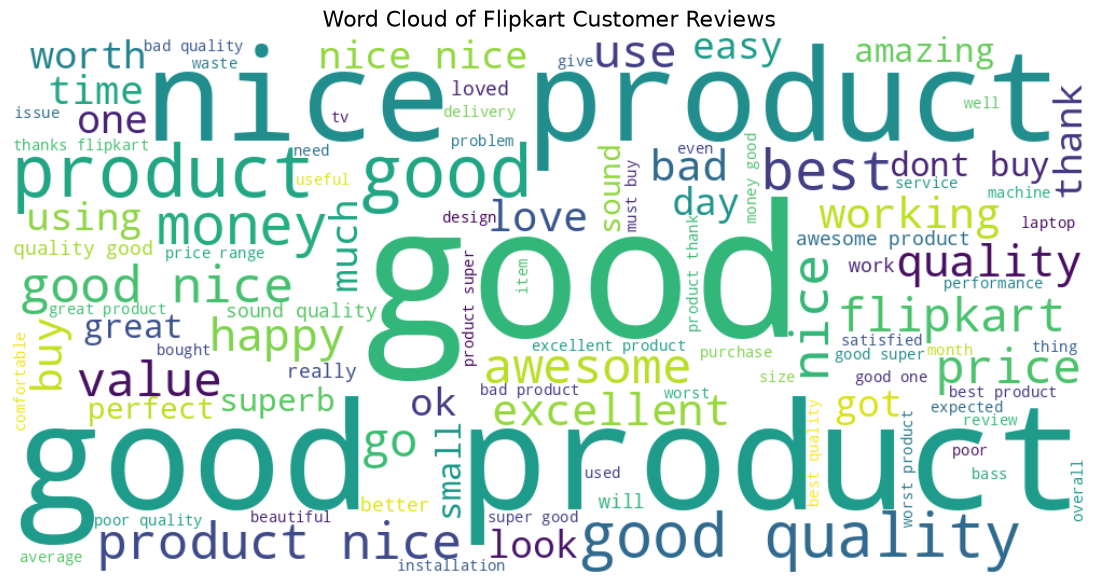

In [9]:
# Combine all customer review summaries into a single text
text = " ".join(
    df['Summary'].dropna().astype(str)
)

# Define stopwords
stopwords = set(STOPWORDS)

# Generate Word Cloud
wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color='white',
    stopwords=stopwords,
    colormap='viridis',
    max_words=100
).generate(text)

# Display the Word Cloud
plt.figure(figsize=(15, 7))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud of Flipkart Customer Reviews', fontsize=16)
plt.show()